In [20]:
import pandas as pd 
import matplotlib.pyplot as plt


## EDA analisys

Let's download our csv in our project. And explore it's 10 first lines&

In [21]:
df = pd.read_csv("../data/waimai_10k.csv")

In [22]:
df.head(10)

,label,review
0,1,很快，好吃，味道足，量大
1,1,没有送水没有送水没有送水
2,1,非常快，态度好。
3,1,方便，快捷，味道可口，快递给力
4,1,菜味道很棒！送餐很及时！
5,1,今天师傅是不是手抖了，微辣格外辣！
6,1,"送餐快,态度也特别好,辛苦啦谢谢"
7,1,超级快就送到了，这么冷的天气骑士们辛苦了。谢谢你们。麻辣香锅依然很好吃。
8,1,经过上次晚了2小时，这次超级快，20分钟就送到了……
9,1,最后五分钟订的，卖家特别好接单了，谢谢。


Here we can see the first 10 rows of the dataset. The dataset contains information about various food delivery orders with 2 columns label and review(aclual reviews of delivery service(外卖)).


In [23]:
# Use the info() method to get a concise summary of the DataFrame, including the number of non-null entries and data types for each column.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11987 entries, 0 to 11986
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   11987 non-null  int64 
 1   review  11987 non-null  object
dtypes: int64(1), object(1)
memory usage: 187.4+ KB


Here we have 2 columns. "label"- it's our target column, then there is "review". Here we can see both of columns don't have missing values. We have to data types - int and object. Dataset contains 11,987 delivery reviews (外卖) with a sentiment label.

In [24]:
# Let's check the variaty of data in target column 'label' to see if it is a binary classification problem or multi-class classification problem.
df['label'].unique()

array([1, 0])

So, the target parameter contains only 1 and 0, we can say it's an bynary classification problem. Need to check the distribution of values in a target variable. 1 - is a good review, 0 - is a bad one.

In [25]:
df['label'].value_counts(normalize=True)

label
0    0.666305
1    0.333695
Name: proportion, dtype: float64

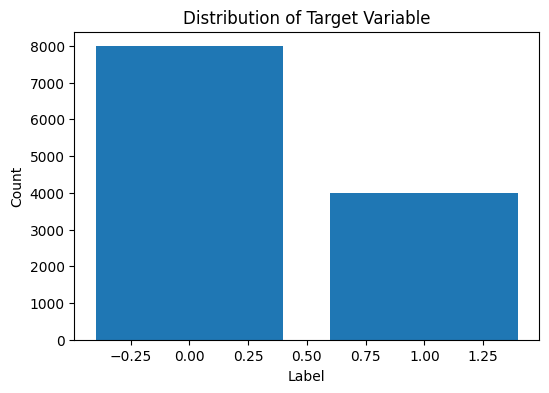

In [26]:
# Build the vizualization of the distribution of the target variable 'label' using a bar chart.
label_counts = df['label'].value_counts()
plt.figure(figsize=(6,4))
plt.bar(label_counts.index, label_counts.values)
plt.xlabel('Label')
plt.ylabel('Count')
plt.title('Distribution of Target Variable')
plt.show()

Classes are imbalanced: label 0 (negative) makes up ~67% (~8,000 rows), label 1 (positive) ~33% (~4,000 rows). A dummy model that always predicts 0 would get ~0.67 accuracy, so this is the baseline our models must beat.

Let's check the duplicates in the both columns

In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
df.duplicated(subset=['review', 'label']).sum()

np.int64(0)

In [29]:
df.duplicated(subset="review").sum()

np.int64(7)

No exact duplicates (text + label), but 7 reviews appear twice with conflicting labels.
 Let's watch those rows.

In [30]:
dups = df[df.duplicated(subset="review", keep=False)].sort_values("review")
print(dups)

       label  review
1459       1   不怎么好吃
8941       0   不怎么好吃
1207       1   不错很好吃
8543       0   不错很好吃
981        1  味道还可以。
4410       0  味道还可以。
1211       1   就是有点慢
5019       0   就是有点慢
3222       1   还是不错的
7048       0   还是不错的
1469       1   送的挺快的
8330       0   送的挺快的
1772       1   速度有点慢
11367      0   速度有点慢


7 reviews appeared twice with conflicting labels. After reading them manually I judged them positive (or mildly critical) and set label = 1, keeping one copy of each. This is a small manual correction (~0.06% of data); the rest of the labels were left as in the original dataset.

In [31]:
mask = df.duplicated(subset="review", keep=False)
df.loc[mask, "label"] = 1
df = df.drop_duplicates(subset="review").reset_index(drop=True)
df.shape

(11980, 2)

In [32]:
# Those 7 reviews deleted. Watch the new the distribution of the target variable
df['label'].value_counts(normalize=True)


label
0    0.66611
1    0.33389
Name: proportion, dtype: float64

After removing duplicates (11,980 rows) the classes are imbalanced: label 0 (negative) ~66.6%, label 1 (positive) ~33.4%. A dummy model that always predicts 0 gets ~0.67 accuracy, so this is the baseline our models must beat.

The riviews have different length, use here len() for count and use describe() for statistic info.

In [33]:
df["len"] = df["review"].str.len()
df["len"].describe()
df.groupby("label")["len"].mean()

label
0    28.885213
1    17.429250
Name: len, dtype: float64

So the average length of good(1) reviews is 28.8, and 17.4 for bad(0) ones.

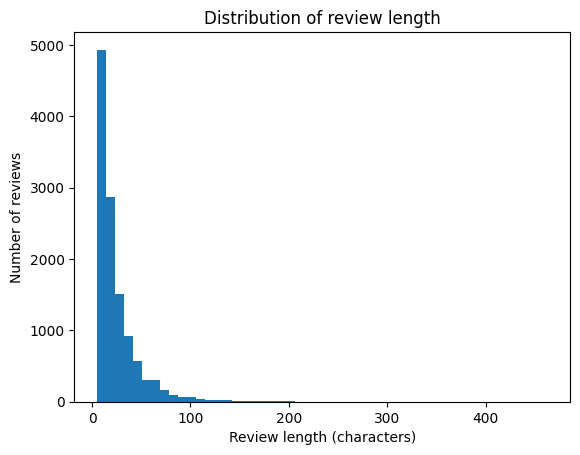

In [34]:

plt.figure()
plt.hist(df["len"], bins=50)
plt.xlabel("Review length (characters)")
plt.ylabel("Number of reviews")
plt.title("Distribution of review length")
plt.show()

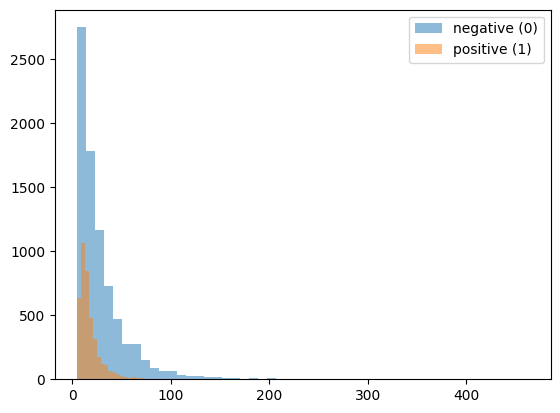

In [35]:
plt.figure()
plt.hist(df[df["label"]==0]["len"], bins=50, alpha=0.5, label="negative (0)")
plt.hist(df[df["label"]==1]["len"], bins=50, alpha=0.5, label="positive (1)")
plt.legend()
plt.show()

In [36]:
# Also let's watch some examples of these 2 types reviews
df[df["label"]==0].sample(5, random_state=1)

,label,review,len
11679,0,不要了还显示送达？,9
7218,0,从下单到送达真的四十分钟，够速度。但是味道确实流汗～而且送餐小哥走时没关门:-D:-D,43
9360,0,送了快2小时，我打电话，老板说送出来，等了40分钟送餐员到了，问送餐的，送餐的说老板做菜慢。...,56
5825,0,"预计送达时间是12:18,晚了半个多小时才送来,还跟我说天冷都慢,由于饿,想着外送员也不容易...",158
10062,0,双拼还凑合，东坡饭太差劲了，肉都是肥的，米饭少还没蔬菜，早知不订了,33


In [37]:
df[df["label"]==1].sample(5, random_state=1)

,label,review,len
200,1,隔三差五儿的就点两杯味道不错！送餐员辛苦啦！,22
1078,1,肘子还是比土豆好吃，坚持吃肉,14
610,1,热干面不好吃。。鹌鹑皮蛋调料汁味道好怪，其它的还挺好，派送员服务很好！,35
2159,1,就是有点咸，，，，其他都是完美的，爱宇宙卷饼,22
1169,1,量还不错，酱汁味道也赞，就是性价比稍微蛋疼了点,23


### Conclusions (EDA)
- Dataset: 11,980 reviews after cleaning, 2 columns (label, review), no missing values.
- Classes are imbalanced: ~67% negative (0), ~33% positive (1). Dummy baseline accuracy ≈ 0.67, so we will focus on recall/F2 of class 0 plus precision.
- 7 reviews had conflicting labels; I set them to 1 after manual reading and kept one copy of each.
- Negative reviews are longer on average (~29 vs ~17 characters).
- Some positive reviews contain mild complaints, so labels are slightly noisy. Negative reviews are clearly negative.